# 12 — The two analysis samples (Stage 2)

Stage 2 of `docs/real_data_roadmap.md`: turn the raw tables audited in notebook 11 into the two lists
the estimator will read.

- **Density tracer (T):** one row per Tempel group, with one center and one radius.
- **Velocity tracer:** one row per CF4 group that passes the cuts, with one peculiar velocity u.

Every later stage reads only these two samples, so a group counted twice, or singletons merged into
one fake group, would corrupt everything downstream without any error.

**Decisions in force** (cut values in `dvcorr.config.SampleConfig`, rule 4):

| Choice | Value | Decided |
| --- | --- | --- |
| Primary richness cut | `Ng ≥ 1`: all groups **and** singletons | 2026-10-15 |
| Velocity u | EDD's `Vpec` ramp with the **natural log** restored | 2026-10-18 (notebook 11 §7, §13) |
| CF4 depth | `Vcmb` < 10,000 km/s (Nusser's cut) | roadmap |
| CF4 sky | inside the SDSS footprint: HEALPix nside-32 pixels holding a Tempel galaxy | roadmap |

**Thin consumer.** The samples are built by `dvcorr.pipeline.real_catalogs`
(`collapse_tempel_groups`, `select_tempel_tracers`, `select_cf4_velocities`, `duplicate_test`,
`sample_counts`). The figures come from `dvcorr.pipeline.real_catalog_audit`. Their docstrings are the
definition site.

In [1]:
%matplotlib inline

import pandas as pd

from dvcorr.config import SampleConfig
from dvcorr.pipeline import real_catalog_audit as audit
from dvcorr.pipeline.real_catalogs import (
    collapse_tempel_groups,
    duplicate_test,
    footprint_pixels,
    load_cf4_groups,
    load_cf4_velocities,
    load_tempel_galaxies,
    sample_counts,
    select_cf4_velocities,
    select_tempel_tracers,
)

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

config = SampleConfig()
tempel = load_tempel_galaxies()
velocities = load_cf4_velocities()
cf4_groups = load_cf4_groups()

tracers = select_tempel_tracers(collapse_tempel_groups(tempel), config)
pixels = footprint_pixels(tempel.table["RA"], tempel.table["DE"], config.footprint_nside)
cf4 = select_cf4_velocities(velocities, cf4_groups, pixels, config)
print(config)
print(f"Tempel density tracers: {len(tracers):,}    CF4 velocity tracers: {len(cf4.table):,}")

SampleConfig(velocity_cz_max=10000.0, min_richness=1, footprint_nside=32, velocity_definition='vpec_ln')
Tempel density tracers: 179,681    CF4 velocity tracers: 4,480


## 1 — Tempel: one row per group

`collapse_tempel_groups` applies the three Tempel traps from notebook 11 §3:

- **Trap 1:** `IDg = 0` is shared by every isolated galaxy, so it is not an identity. Real groups are keyed
  by `IDg > 0`; each singleton is its own tracer, keyed by its galaxy `ID`.
- **Trap 2:** the center is the member with the **lowest `Rg` present**. That is `Rg = 1`, unless the
  clipped table dropped the brightest member (375 groups). Rows are grouped by `IDg`, never by row count,
  so the 402 groups with `Ng ≥ 2` left as a single row stay groups.
- **Trap 4:** the radius is `dc`, constant within every group (the function raises if it is not). `gVcmb`
  is not used. For the counts below, a group's redshift is `cz_cmb` = c × the mean member `zcmb`, which
  is the redshift `dc` encodes (to ~2 km/s wherever no member was clipped).

The first rows show each case. `IDg = 1` has `Ng = 7` but only one row left, its `Rg = 5` member:
it stays a group, centered on that member. The last rows are singletons.

*Verify yourself:* `tempel.table.query("IDg == 1")` has a single row with `Rg = 5`.

In [2]:
display(tracers.head(4))
display(tracers[tracers.is_singleton].head(3))
tracers.groupby("is_singleton").agg(tracers=("ID", "size"), median_Ng=("Ng", "median"),
                                    rows_present=("n_members", "sum"))

,IDg,ID,pgc,is_singleton,Ng,n_members,center_Rg,RA,DE,glon,glat,dc,cz_cmb
0,1,408210,4154791,False,7,1,5,121.9474,16.3940,206.1298,24.0735,438.29,29910.293535
1,5,7,4581691,False,19,19,1,163.4606,16.8498,227.5155,60.9578,371.96,25737.024734
2,14,19,1396685,False,15,15,1,206.0967,11.6491,344.2605,70.1471,416.22,28873.211492
3,15,21,140689,False,38,11,1,255.6770,34.0600,56.7866,36.3134,439.50,29644.023324


,IDg,ID,pgc,is_singleton,Ng,n_members,center_Rg,RA,DE,glon,glat,dc,cz_cmb
49671,0,5,1739055,True,1,1,1,242.5413,25.5061,42.5773,45.7316,321.77,22202.629439
49672,0,10,169917,True,1,1,1,210.6114,9.6390,350.0529,65.7826,368.76,25512.338176
49673,0,15,53822,True,1,1,1,226.1649,26.9771,40.3953,60.4268,137.54,9392.497709


,tracers,median_Ng,rows_present
is_singleton,,,
False,49671,2.0,175942
True,130010,1.0,130010


Every one of the 305,952 galaxy rows lands in exactly one tracer: 175,942 rows in groups plus 130,010
singletons. The `rows_present` column sums back to the table.

## 2 — CF4: the velocity sample

`select_cf4_velocities` joins the two CF4 files row by row (it raises if their `pgc` order differs). Then:

1. it keeps `Vcmb` < 10,000 km/s, using the velocities file, from which `fV` and u are built;
2. it keeps groups inside the SDSS footprint, using the groups file's positions (the velocities file has
   pgc 51922 at the wrong position, notebook 11 §2);
3. it computes u = w·Vpds + (1 − w)·v_WF, with v_WF in the natural log and w = clip(1 − Vls/3000, 0, 1);
4. it **drops** any group whose u is undefined, rather than filling it (rule 5).

`sigma_u` is the eDM error of the ln velocity. The calibrator groups have eDM = 0 ("not given"), so
their `sigma_u` is NaN. They are kept: Nusser's weight w = 1 needs no error.

In [3]:
print(f"dropped for undefined u: {cf4.n_undefined_velocity}  (pgc {cf4.undefined_pgc})")
display(velocities.table[velocities.table.pgc.isin(cf4.undefined_pgc)][
    ["pgc", "Vcmb", "Vls", "fV", "DMzp", "eDM", "Vpds", "Vpwf", "Vpec"]])
cf4.table.describe().T[["count", "min", "50%", "max"]].round(1)

dropped for undefined u: 1  (pgc (39346,))


,pgc,Vcmb,Vls,fV,DMzp,eDM,Vpds,Vpwf,Vpec
6499,39346,0,94,0,28.17,0.0,-321,0,-311


,count,min,50%,max
pgc,4480.0,21014.0,47411.0,6726347.0
RA,4480.0,111.6,182.4,262.2
DE,4480.0,-5.9,22.6,70.4
glon,4480.0,0.1,195.2,359.8
glat,4480.0,17.8,58.2,89.4
Vcmb,4480.0,-61.0,6730.5,9997.0
Vls,4480.0,-23.0,6408.0,10110.0
fV,4480.0,-61.0,6850.5,10260.0
DMzp,4480.0,24.3,34.7,37.1
eDM,4480.0,0.0,0.4,0.9


**The one dropped group** is pgc 39346: a calibrator (eDM = 0) at `Vcmb` = 0, about 4 Mpc away. At
fV = 0 the log in v_WF is undefined. EDD's published `Vpec` (−311) blends in the filler 0 that the file
writes there, with weight 0.03. That 0 is not a velocity, so the group is dropped. The group with
fV < 0 (pgc 2801026, `Vcmb` = −61) is kept with u = `Vpds`, as EDD's own rule does.

The sample is what Nusser's selection should give: `Vcmb` from −61 to 9,997 km/s, u centered near zero
(median −50 km/s), and σ_u from 5 km/s for the nearest groups to 3,800 km/s at the cut.

## 3 — The duplicate test

The methodological note (§6.2) requires one Tempel row per group identifier and one CF4 row per
identifier. `duplicate_test` checks four keys. The last Tempel row is the strongest: every tracer's
center galaxy `ID` is unique, so no galaxy centers two tracers.

In [4]:
dupes = duplicate_test(tracers, cf4)
display(dupes)
assert (dupes["duplicates"] == 0).all()

,rows,unique_keys,duplicates
key,,,
"Tempel groups, by IDg",49671,49671,0
"Tempel singletons, by ID",130010,130010,0
"Tempel tracers, by center ID",179681,179681,0
"CF4 groups, by pgc",4480,4480,0


## 4 — Counts against the roadmap

`sample_counts` gives both funnels. The "cz < 10,000" Tempel rows are for comparison only: **the density
sample is not cut in depth**, because it has to reach past the deepest velocity center by the largest shell
radius.

In [5]:
sample_counts(tracers, cf4, config)

,count
sample,
Tempel real groups (IDg > 0),49671
Tempel singletons (IDg = 0),130010
"Tempel density tracers, Ng >= 1",179681
"Tempel groups at cz < 10,000",6360
"Tempel singletons at cz < 10,000",15272
Tempel groups centered on Rg > 1 (Trap 2 fallback),375
CF4 groups (files),38057
"CF4 groups at Vcmb < 10,000",12126
"CF4 groups at Vcmb < 10,000, inside the SDSS footprint",4481


| Roadmap *Expect (measured)* | Measured | Verdict |
| --- | --- | --- |
| 49,671 real groups | 49,671 | agrees |
| 130,010 singletons | 130,010 | agrees |
| 6,367 groups with Ng ≥ 2 at cz < 10,000 | **6,360** | differs by 7, explained below |
| 15,278 singletons at cz < 10,000 | **15,272** | differs by 6, explained below |
| 4,481 CF4 objects inside the footprint | 4,481 before the velocity cut; **4,480** in the sample | agrees; one group dropped for undefined u |
| 375 groups without `Rg = 1` (Stage 1) | 375 centered on Rg > 1 | agrees |

**Why the two Tempel cz counts differ.** The roadmap counted at cz < 10,000 using each center's
`gVcmb`. That column is not the Tempel group velocity:

- it varies between members of one group in 19% of groups (Trap 4);
- for **243 singletons** it differs by more than 500 km/s from the galaxy's own c·`zcmb`, and in one
  case by 17,174 km/s (pgc 26782: c·zcmb = 2,262 km/s, `gVcmb` = 7,713 km/s). It looks like a velocity
  carried over from a different grouping.

The redshift Tempel actually used for a group is the one in `dc`. For complete groups, `dc` equals
χ(mean member `zcmb`) in Tempel's Planck cosmology (H0 = 67.8, Ωm = 0.308) to ≤ 1.8 km/s. Cutting on
that mean gives 6,360 groups, the same count as inverting `dc` directly (checked outside this notebook;
the χ(z) inversion is Stage 3's job). Singletons cut on their own `zcmb` give 15,272. The 7 and 6
objects of difference are boundary groups whose `gVcmb` falls on the other side of 10,000 km/s.

**Not a difference: 6,367 "groups with Ng ≥ 2".** Every group with `IDg > 0` has `Ng ≥ 2` (the
minimum is 2), so "groups with Ng ≥ 2" and "real groups" are the same set.

## 5 — Sky plot of both samples at cz < 10,000 km/s

Tempel tracers are drawn first (at the bottom), CF4 velocity tracers on top, both cut at cz < 10,000
km/s in the CMB frame. **What right looks like:** every CF4 point sits on the Tempel cap. CF4 groups that
spill outside it would mean the footprint test is broken. Inside the cap, both should trace the same
large-scale structure: the Coma–A1367 filament near RA 180–195°, δ ≈ 20–30°, and the Virgo cluster
near RA 187°, δ 12°.

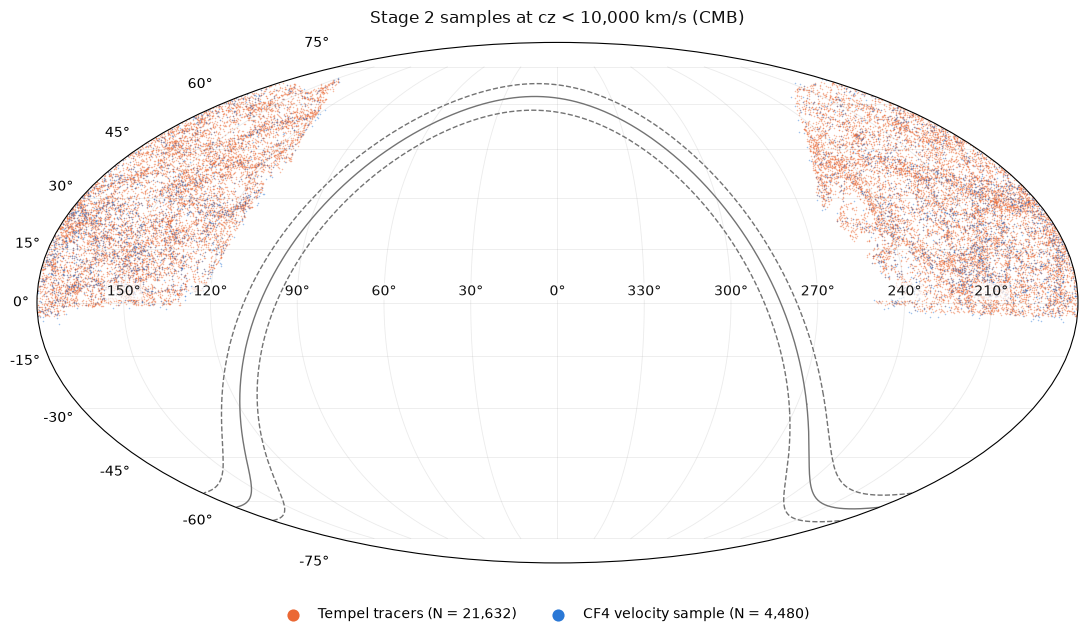

In [6]:
sky = [audit.tempel_tracer_sky_sample(tracers), audit.cf4_velocity_sky_sample(cf4)]
fig = audit.make_overlap_sky_map(sky, title="Stage 2 samples at cz < 10,000 km/s (CMB)",
                                 cz_max=config.velocity_cz_max)

**Reading it.** The CF4 points lie only on the Tempel cap, which satisfies the roadmap's *Done when*
condition. Inside the cap they follow the same filaments as the Tempel tracers. By construction, every CF4 group kept
lies in an nside-32 pixel (3.4 deg², ~1.8° across) that holds at least one Tempel galaxy. At the edge of
the cap, such a pixel can reach up to one pixel width past the last galaxy, so the footprint is slightly
generous there. Stage 4 replaces it with the real angular mask.

**n(cz) of the two samples.** The Tempel tracers run to the survey limit, z = 0.1. The CF4 velocity
tracers stop at the 10,000 km/s cut. Note how much deeper the density field reaches: it has to, because a
center at 10,000 km/s needs density tracers out to 10,000 + 64·100 km/s (64 h⁻¹ Mpc is the largest shell
radius, rule 10).

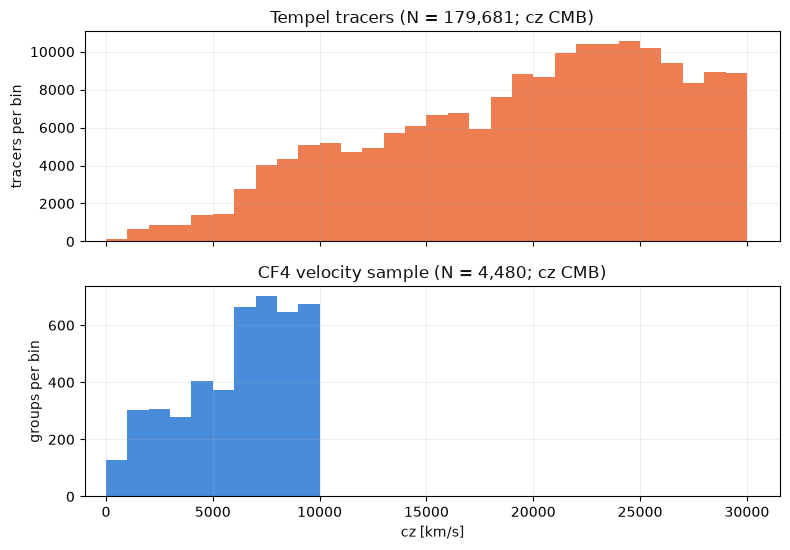

In [7]:
fig = audit.make_cz_histogram_figure(sky)

## Done when — status

| Stage 2 *Done when* | Status |
| --- | --- |
| Duplicate test passes (one row per group and per CF4 object) | **passes** (section 3; also a pytest gate) |
| Counts match | **match**, apart from 6,360 / 15,272 against the roadmap's 6,367 / 15,278, explained in section 4 |
| Sky plot shows CF4 centers inside the Tempel footprint | **yes** (section 5) |
| **[2026-10-14]** the same for the 2MRS density field (M), counts matrix filled | **not started** |
| **[2026-10-14]** Phase B per-source velocity samples | **blocked**: the CF4 individual-galaxy table is not in `data/` |

The T × CF4-groups half of Stage 2 is done. The M half (2MRS as the density field, CF4 inside the 2MRS
mask: 12,077 groups at cz < 10,000 in notebook 11 §10) uses the same CF4 builder with a different
footprint.